# Reto 3 · Modelo de clustering K-Means

**Malackathon 2026 · Mercedes-Benz · "Clustering the Star"**

Objetivo: agrupar a los clientes en segmentos homogéneos con K-Means, elegir de forma justificada cuántos segmentos crear y entrenar el modelo final.
Este notebook cubre:

1. Datos de partida
2. Exploración del número de clústeres (k de 2 a 20)
3. Método del codo y coeficiente de silueta
4. Métricas de apoyo y tamaño de los segmentos
5. Selección del k óptimo
6. Modelo final y distribución de clientes

## 1. Datos de partida

Trabajamos con dos tablas generadas en el cuaderno 02:

- **`df_prepared`**: la matriz que recibe el modelo. Tiene una fila por cliente y las 18 columnas ya codificadas y escaladas
  (antigüedad del vehículo, antigüedad como cliente, uso del taller, conectividad, poder adquisitivo, edad, gama, furgoneta, telemetría,
  financiación y motorización).
- **`df`**: la tabla de clientes en unidades originales. No entra en el modelo; la usamos para añadir el clúster de cada cliente y describir los segmentos.

El escalado es imprescindible porque K-Means agrupa por **distancia**: sin él, una variable en euros (poder adquisitivo) pesaría miles de veces
más que una en años.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import plot_style as ps
import mb_features as mf

ps.apply()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Matriz escalada que recibe el modelo y tabla de clientes en unidades originales
df_prepared = pd.read_pickle(DATA_DIR / "X_model_fe2.pkl")
df = pd.read_csv(DATA_DIR / "clientes_features.csv", low_memory=False).set_index("client_id")

# Comprobamos que ambas tablas tienen los mismos clientes en el mismo orden
assert df_prepared.index.equals(df.index)
X = df_prepared.values
print(f"Clientes: {X.shape[0]:,} · columnas del modelo: {X.shape[1]}")
df_prepared.describe().T[["mean", "50%", "min", "max"]].round(2)

Clientes: 173,456 · columnas del modelo: 18


,mean,50%,min,max
warranty_visit_frequency,-0.03,0.0,-0.66,1.95
digital_engagement_index,-0.02,0.0,-1.10,2.04
purchasing_power_per_household_eur,-0.10,0.0,-1.57,2.24
main_vehicle_age_years,0.09,0.0,-0.94,4.93
tenure_years,-0.07,0.0,-1.24,2.90
age_range,-0.02,0.0,-1.50,1.00
main_segment_tier,-0.12,0.0,-1.00,2.00
main_is_van,0.11,0.0,0.00,1.00
has_telemetry,0.60,1.0,0.00,1.00
finance_leasing_status_active_FL_and_CASH,0.02,0.0,0.00,1.00


## 2. Exploración del número de clústeres (k de 2 a 20)

K-Means necesita que le digamos de antemano cuántos grupos queremos (**k**). Coloca k centros, asigna cada cliente al centro más cercano,
recoloca cada centro en el punto medio de sus clientes y repite hasta que nada cambia. Como no sabemos cuál es el k adecuado, entrenamos
un modelo para cada valor entre 2 y 20 y medimos su calidad con cuatro métricas:

| Métrica | Qué mide | Mejor cuanto… |
|---|---|---|
| **Inercia** | Suma de distancias de cada cliente a su centro: lo compactos que son los grupos | más baja (pero siempre baja al subir k) |
| **Silueta** | Si cada cliente está más cerca de su grupo que del grupo vecino (de −1 a 1) | más alta |
| **Davies-Bouldin** | Parecido entre cada grupo y su grupo más similar | más baja |
| **Calinski-Harabasz** | Separación entre grupos frente a dispersión dentro de ellos | más alta |

Usamos `random_state=42` para que los resultados sean reproducibles y `n_init=10` para que cada modelo pruebe 10 posiciones iniciales y se quede
con la mejor, lo que evita resultados malos por azar.

La silueta compara cada cliente con todos los demás: con 173.456 clientes serían unos 30.000 millones de distancias por cada k. Por eso la
calculamos sobre **3 muestras aleatorias de 20.000 clientes** y promediamos; la desviación entre muestras nos dice si la estimación es estable.
El resto de métricas se calculan con todos los clientes.

In [2]:
K_RANGE = range(2, 21)
rng = np.random.default_rng(42)
muestras = [rng.choice(len(X), 20_000, replace=False) for _ in range(3)]   # muestras fijas para todos los k

resultados, etiquetas = [], {}
for k in K_RANGE:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    etiquetas[k] = modelo.labels_                                          # guardamos las etiquetas para comparar k después
    siluetas = [silhouette_score(X[m], modelo.labels_[m]) for m in muestras]
    tamanos = np.bincount(modelo.labels_) / len(X) * 100
    resultados.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silueta": np.mean(siluetas),
        "silueta_desv": np.std(siluetas),
        "davies_bouldin": davies_bouldin_score(X, modelo.labels_),
        "calinski_harabasz": calinski_harabasz_score(X, modelo.labels_),
        "segmento_menor_%": tamanos.min(),
        "segmento_mayor_%": tamanos.max(),
    })

res = pd.DataFrame(resultados).set_index("k")
res.round({"inercia": 0, "silueta": 4, "silueta_desv": 4, "davies_bouldin": 3, "calinski_harabasz": 0,
           "segmento_menor_%": 1, "segmento_mayor_%": 1})

,inercia,silueta,silueta_desv,davies_bouldin,calinski_harabasz,segmento_menor_%,segmento_mayor_%
k,,,,,,,
2,684253.0,0.1054,0.0007,2.783,21187.0,42.5,57.5
3,622708.0,0.1060,0.0005,2.514,20212.0,21.6,41.2
4,577786.0,0.1090,0.0005,2.276,19017.0,21.0,29.4
5,540424.0,0.1107,0.0004,2.031,18247.0,18.7,22.5
6,515542.0,0.1100,0.0001,1.963,16976.0,12.4,19.3
7,500786.0,0.1025,0.0001,2.107,15415.0,10.7,17.8
8,486648.0,0.1031,0.0001,2.168,14317.0,8.4,17.4
9,475155.0,0.0996,0.0003,2.276,13355.0,8.2,14.8
10,463373.0,0.1018,0.0004,2.047,12662.0,7.4,15.6


La desviación de la silueta entre muestras es del orden de diezmilésimas, así que las diferencias de silueta entre valores de k que veremos
a continuación son reales y no fruto del muestreo.

## 3. Método del codo y coeficiente de silueta

Para localizar el **codo** de forma objetiva usamos el método *kneedle*: normalizamos la curva de inercia entre 0 y 1 y buscamos el k que
más se aleja de la recta que une el primer y el último punto. Ese es el punto donde añadir clústeres deja de reducir la inercia de forma notable.

En la silueta destacamos los **picos**: los k cuya silueta es mayor que la de sus dos vecinos.

Codo sugerido: k = 6 · silueta máxima: k = 5 (0.1107) · picos de silueta: [5, 8, 10, 13, 16, 18]


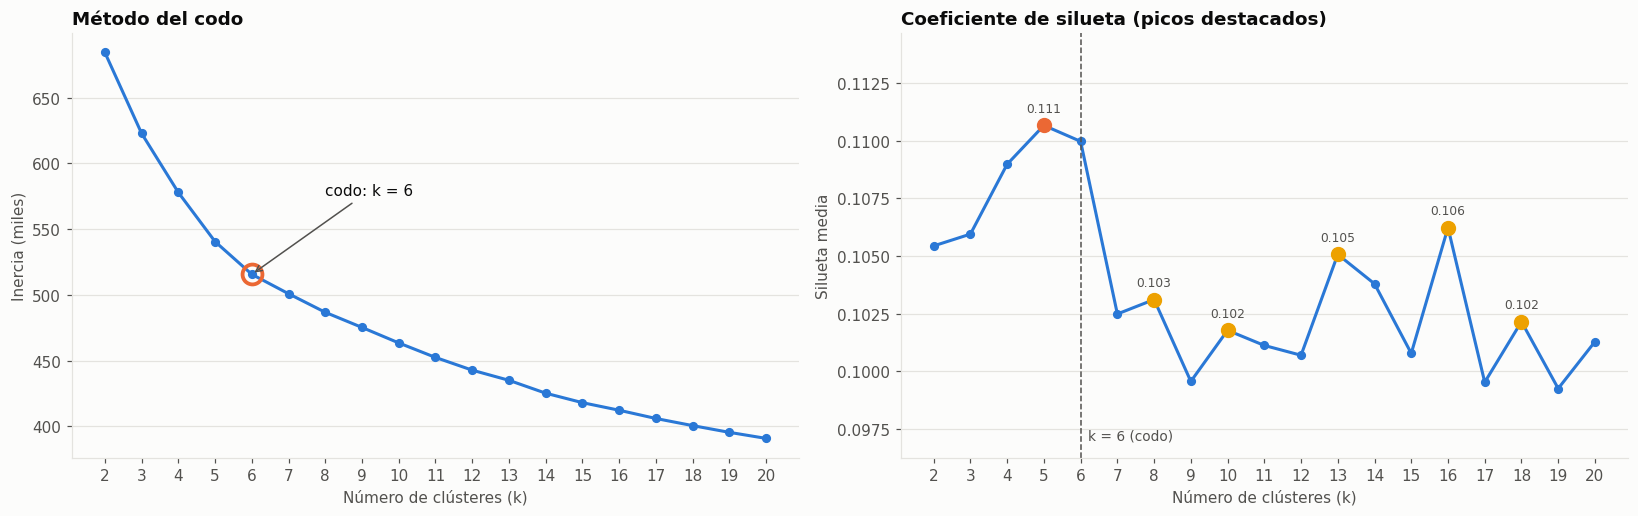

In [3]:
# Codo (kneedle): punto de la curva normalizada más alejado de la diagonal
ks = res.index.to_numpy(dtype=float)
xn = (ks - ks.min()) / (ks.max() - ks.min())
yn = (res.inercia - res.inercia.min()) / (res.inercia.max() - res.inercia.min())
k_codo = int(ks[np.argmax(np.abs(yn.to_numpy() - (1 - xn)))])

# Picos de silueta: mayores que sus dos vecinos
s = res.silueta
picos = [k for k in s.index[1:-1] if s[k] > s[k - 1] and s[k] > s[k + 1]]
k_sil = int(s.idxmax())
print(f"Codo sugerido: k = {k_codo} · silueta máxima: k = {k_sil} ({s.max():.4f}) · picos de silueta: {picos}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ax = axes[0]
ax.plot(res.index, res.inercia / 1e3, marker="o", ms=5, lw=2, color=ps.SERIES[0])
ax.plot(k_codo, res.inercia[k_codo] / 1e3, "o", ms=13, mfc="none", mec=ps.SERIES[1], mew=2.5)
ax.annotate(f"codo: k = {k_codo}", (k_codo, res.inercia[k_codo] / 1e3), xytext=(k_codo + 2, res.inercia[k_codo] / 1e3 + 60),
            arrowprops=dict(arrowstyle="->", color=ps.INK_2), color=ps.INK, fontsize=10)
ax.set_title("Método del codo"); ax.set_xlabel("Número de clústeres (k)"); ax.set_ylabel("Inercia (miles)")
ax.set_xticks(list(K_RANGE))

ax = axes[1]
ax.plot(res.index, s, marker="o", ms=5, lw=2, color=ps.SERIES[0])
for k in picos:
    ax.plot(k, s[k], "o", ms=9, color=ps.SERIES[1] if k == k_sil else ps.SERIES[3])
    ax.annotate(f"{s[k]:.3f}", (k, s[k]), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8, color=ps.INK_2)
ax.axvline(k_codo, color=ps.INK_2, ls="--", lw=1)
ax.text(k_codo + 0.2, s.min() - 0.0022, f"k = {k_codo} (codo)", color=ps.INK_2, fontsize=9)
ax.set_ylim(s.min() - 0.003, s.max() + 0.004)
ax.set_title("Coeficiente de silueta (picos destacados)"); ax.set_xlabel("Número de clústeres (k)"); ax.set_ylabel("Silueta media")
ax.set_xticks(list(K_RANGE))
fig.tight_layout(); fig.savefig(FIG_DIR / "03b_codo_silueta.png"); plt.show()

**Cómo leer los gráficos:**

- **Codo:** la inercia cae con fuerza hasta k = 6 y a partir de ahí la curva se aplana: cada clúster adicional aporta cada vez menos
  compactación. El método kneedle sitúa el codo en **k = 6**.
- **Silueta:** el máximo está en **k = 5** y k = 6 queda prácticamente empatado (diferencia inferior a una milésima). A partir de k = 7 la
  silueta cae y no vuelve a recuperar esos valores, aunque hay picos menores en k más altos.

Los valores de silueta son bajos en todo el rango (en torno a 0,10-0,11). Es lo habitual con datos reales de clientes: no forman grupos
aislados, sino un continuo en el que unos clientes se parecen más que otros. Por eso la silueta sirve para **comparar** valores de k entre sí,
no como nota absoluta.

## 4. Métricas de apoyo y tamaño de los segmentos

Completamos el análisis con Davies-Bouldin, Calinski-Harabasz y con una métrica de negocio: el tamaño del **segmento más pequeño**.
Un segmento con muy pocos clientes es difícil de rentabilizar con una campaña propia.

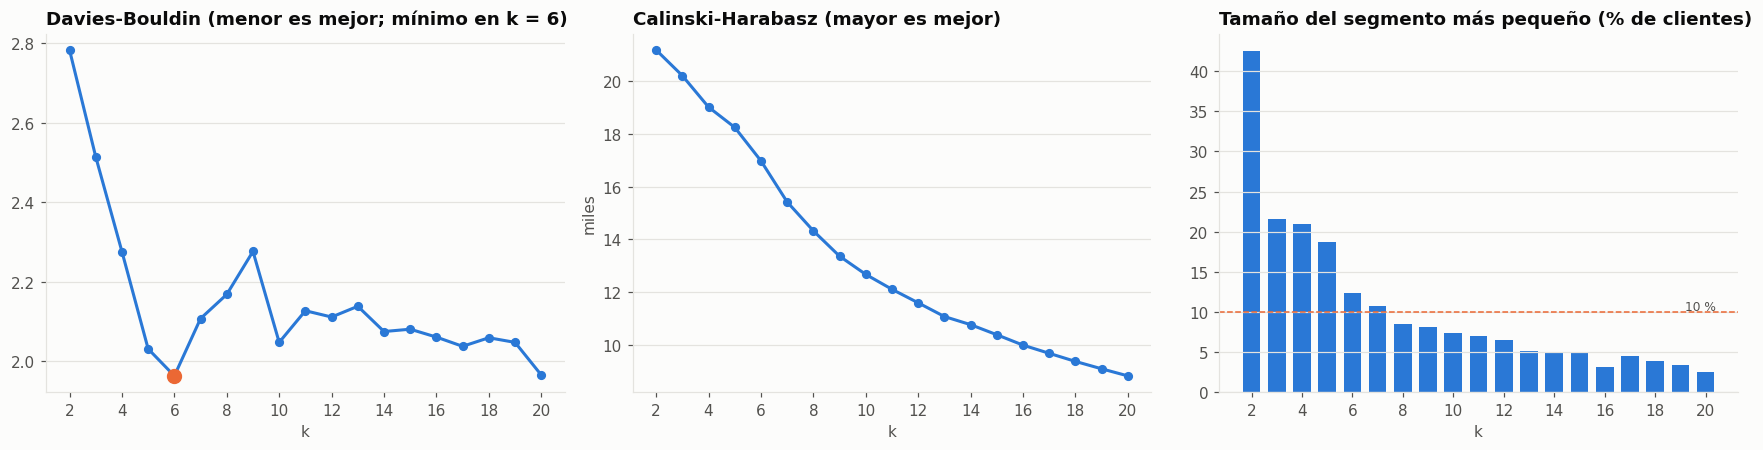

Davies-Bouldin mínimo: k = 6 (1.963)


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
ax = axes[0]
ax.plot(res.index, res.davies_bouldin, marker="o", ms=5, lw=2, color=ps.SERIES[0])
k_db = int(res.davies_bouldin.idxmin())
ax.plot(k_db, res.davies_bouldin[k_db], "o", ms=9, color=ps.SERIES[1])
ax.set_title(f"Davies-Bouldin (menor es mejor; mínimo en k = {k_db})"); ax.set_xlabel("k"); ax.set_xticks(list(K_RANGE)[::2])

ax = axes[1]
ax.plot(res.index, res.calinski_harabasz / 1e3, marker="o", ms=5, lw=2, color=ps.SERIES[0])
ax.set_title("Calinski-Harabasz (mayor es mejor)"); ax.set_xlabel("k"); ax.set_ylabel("miles"); ax.set_xticks(list(K_RANGE)[::2])

ax = axes[2]
ax.bar(res.index, res["segmento_menor_%"], color=ps.SERIES[0], width=0.7)
ax.axhline(10, color=ps.SERIES[1], ls="--", lw=1)
ax.text(20.4, 10.3, "10 %", color=ps.INK_2, fontsize=8, ha="right")
ax.set_title("Tamaño del segmento más pequeño (% de clientes)"); ax.set_xlabel("k"); ax.set_xticks(list(K_RANGE)[::2])
fig.tight_layout(); fig.savefig(FIG_DIR / "03b_metricas_apoyo.png"); plt.show()
print(f"Davies-Bouldin mínimo: k = {k_db} ({res.davies_bouldin.min():.3f})")

- **Davies-Bouldin** alcanza su mejor valor en **k = 6**: es el k con los grupos menos parecidos entre sí.
- **Calinski-Harabasz** baja de forma continua al aumentar k. Esta métrica favorece sistemáticamente los k pequeños, así que no discrimina
  por sí sola y la usamos solo como contexto.
- **Tamaño mínimo:** hasta k = 6 el segmento más pequeño supera el 12 % de la base. A partir de k = 8 el más pequeño baja del 10 % y desde k = 14 aparecen
  segmentos por debajo del 5 %: la base se fragmenta en grupos demasiado pequeños para justificar acciones comerciales propias.

## 5. Selección del k óptimo

Las métricas señalan dos candidatos: **k = 5** (mejor silueta) y **k = 6** (codo y mejor Davies-Bouldin). Los comparamos en detalle:

In [5]:
candidatos = res.loc[[4, 5, 6, 7, 8], ["inercia", "silueta", "davies_bouldin", "segmento_menor_%", "segmento_mayor_%"]]
candidatos.round({"inercia": 0, "silueta": 4, "davies_bouldin": 3, "segmento_menor_%": 1, "segmento_mayor_%": 1})

,inercia,silueta,davies_bouldin,segmento_menor_%,segmento_mayor_%
k,,,,,
4,577786.0,0.1090,2.276,21.0,29.4
5,540424.0,0.1107,2.031,18.7,22.5
6,515542.0,0.1100,1.963,12.4,19.3
7,500786.0,0.1025,2.107,10.7,17.8
8,486648.0,0.1031,2.168,8.4,17.4


Para decidir entre 5 y 6 desde el punto de vista del negocio, vemos **qué cambia al pasar de 5 a 6 clústeres**: cada fila es un clúster
de k = 5 y cada columna, a qué clúster de k = 6 van sus clientes.

In [6]:
paso = pd.crosstab(pd.Series(etiquetas[5], name="clúster con k = 5"), pd.Series(etiquetas[6], name="clúster con k = 6"),
                   normalize="index").mul(100).round(0)
display(paso)

perfil6 = df.assign(cluster=etiquetas[6]).groupby("cluster").agg(
    clientes_pct=("tenure_years", lambda x: len(x) / len(df) * 100),
    antiguedad_vehiculo=("main_vehicle_age_years", "median"),
    financiacion_activa_pct=("finance_leasing_status", lambda x: x.str.startswith("active").mean() * 100),
    telemetria_pct=("has_telemetry", lambda x: x.mean() * 100),
    electrificado_pct=("main_engine_concept", lambda x: x.isin(["ELECTRIC", "PLUGIN_HYBRID"]).mean() * 100),
).round(1)
print("Perfil rápido de los clústeres con k = 6:")
perfil6

clúster con k = 6,0,1,2,3,4,5
clúster con k = 5,,,,,,
0,0.0,0.0,0.0,86.0,13.0,1.0
1,0.0,77.0,0.0,0.0,22.0,0.0
2,0.0,0.0,0.0,1.0,17.0,82.0
3,1.0,1.0,94.0,1.0,0.0,3.0
4,89.0,0.0,0.0,1.0,9.0,1.0


Perfil rápido de los clústeres con k = 6:


,clientes_pct,antiguedad_vehiculo,financiacion_activa_pct,telemetria_pct,electrificado_pct
cluster,,,,,
0,16.9,2.1,9.8,43.4,35.5
1,15.1,3.6,35.1,71.0,36.4
2,18.4,2.5,96.3,64.6,25.2
3,17.8,5.8,2.5,60.8,9.6
4,12.4,9.1,1.6,43.0,1.3
5,19.3,5.1,4.2,71.8,19.4


### Justificación

**Para el jurado técnico.** Elegimos **k = 6** porque es el único valor en el que coinciden varias señales:

- Es el **codo** de la curva de inercia: a partir de aquí, más clústeres apenas mejoran la compactación.
- Tiene el **mejor índice Davies-Bouldin** de todo el rango: son los grupos mejor diferenciados entre sí.
- Su **silueta** (0,110) está a menos de una milésima del máximo (k = 5, 0,111), una diferencia sin relevancia práctica.

**Para el equipo de marketing.** Seis segmentos es un número que un equipo puede gestionar con estrategias diferenciadas, y todos son
suficientemente grandes (el menor supera el 12 % de los clientes). Además, el sexto clúster es muy accionable: al pasar de 5 a 6 aparece
un grupo (el clúster 4) que reúne a los clientes con el **vehículo más antiguo** (unos 9 años), casi **sin financiación activa**, con menos
telemetría que la media y prácticamente sin vehículos electrificados. Con k = 5 estos clientes estaban repartidos entre cuatro segmentos;
con k = 6 forman un público claro para las **campañas de renovación**.

Por encima de k = 8 la base se fragmenta (el segmento más pequeño baja del 10 % de los clientes) y empiezan a diferenciarse por matices que no justifican
campañas distintas: más segmentos no significan mejor segmentación.

## 6. Modelo final y distribución de clientes

Entrenamos K-Means con **k = 6** y los mismos parámetros que en la exploración, y añadimos la etiqueta de clúster a cada cliente en `df['cluster']`.

In [7]:
K_FINAL = 6
kmeans_final = KMeans(n_clusters=K_FINAL, n_init=10, random_state=42).fit(X)
df["cluster"] = kmeans_final.labels_

# Mismo resultado que en la exploración (mismos parámetros y semilla)
assert (df["cluster"].to_numpy() == etiquetas[K_FINAL]).all()
print(f"Modelo final: k = {K_FINAL} · inercia = {kmeans_final.inertia_:,.0f} · silueta = {res.silueta[K_FINAL]:.4f}")

Modelo final: k = 6 · inercia = 515,542 · silueta = 0.1100


In [8]:
distribucion = (df["cluster"].value_counts().sort_index().rename("clientes").to_frame()
                .assign(**{"% del total": lambda t: (t.clientes / t.clientes.sum() * 100).round(1)}))
distribucion.index.name = "clúster"
distribucion.loc["Total"] = [distribucion.clientes.sum(), 100.0]
distribucion.astype({"clientes": int})

,clientes,% del total
clúster,,
0,29388,16.9
1,26245,15.1
2,31980,18.4
3,30809,17.8
4,21510,12.4
5,33524,19.3
Total,173456,100.0


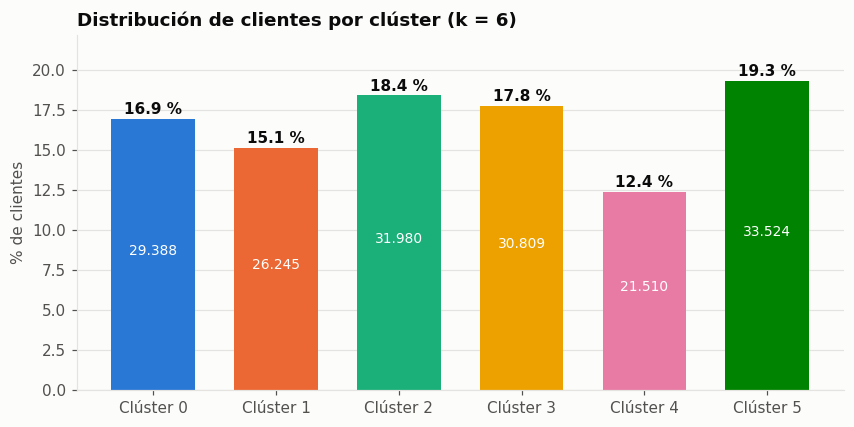

In [9]:
pct = df["cluster"].value_counts(normalize=True).sort_index() * 100
fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.bar([f"Clúster {i}" for i in pct.index], pct.values, color=ps.SERIES[:K_FINAL], width=0.68)
for b, (v, n) in zip(bars, zip(pct.values, df["cluster"].value_counts().sort_index().values)):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.3, f"{v:.1f} %", ha="center", fontsize=10, color=ps.INK, fontweight="bold")
    ax.text(b.get_x() + b.get_width() / 2, v / 2, f"{n:,}".replace(",", "."), ha="center", fontsize=9, color="white")
ax.set_ylim(0, pct.max() * 1.15); ax.set_axisbelow(True)
ax.set_ylabel("% de clientes"); ax.set_title(f"Distribución de clientes por clúster (k = {K_FINAL})")
fig.savefig(FIG_DIR / "03b_distribucion_clusters.png"); plt.show()

Los seis segmentos tienen tamaños equilibrados, entre el 12 % y el 19 % de la base: ninguno absorbe a la mayoría de los clientes ni es tan
pequeño que no compense una estrategia propia. Cada barra muestra el porcentaje y, dentro, el número de clientes.

En el siguiente cuaderno (reto 4) describiremos cada clúster en lenguaje de negocio y le daremos un nombre.

In [10]:
import joblib

df.reset_index().to_csv(DATA_DIR / "clientes_clusters.csv", index=False)      # clientes con su clúster, para el reto 4
joblib.dump(kmeans_final, DATA_DIR / "kmeans_final_k6.joblib")
res.to_csv(ROOT / "reports" / "kmeans2_metricas_k.csv")
print("Guardado: data/clientes_clusters.csv, data/kmeans_final_k6.joblib y reports/kmeans2_metricas_k.csv")

Guardado: data/clientes_clusters.csv, data/kmeans_final_k6.joblib y reports/kmeans2_metricas_k.csv


## Resumen

- Exploramos K-Means de **k = 2 a k = 20** con inercia, silueta, Davies-Bouldin y Calinski-Harabasz.
- El **codo** y el mejor **Davies-Bouldin** están en k = 6; la **silueta** máxima en k = 5, prácticamente empatada con k = 6.
- Elegimos **k = 6**: combina las mejores señales técnicas con segmentos equilibrados y añade un grupo de clientes en ventana de renovación.
- El modelo final asigna a cada cliente un clúster en `df['cluster']`; los segmentos representan entre el 12 % y el 19 % de la base.